In [28]:
import laspy
import os
import numpy as np
import open3d as o3d
import geopandas as gpd
import matplotlib.pyplot as plt

<h1>LIDAR data<h1>

<h2>Load a single -laz-file</h2>

In [29]:
path = "data/sample_roofdata_50"
las = laspy.read(path + "/10444144.laz")

<h2>Metadata of a single .laz-file</h2>

In [30]:
print("Antall punkter:", las.header.point_count)
print("Skala:", las.header.scales)
print("Offset:", las.header.offsets)
print("Koordinatgrenser:", las.header.mins, las.header.maxs)
print("CRS:", las.header.parse_crs())

Antall punkter: 1403
Skala: [0.01 0.01 0.01]
Offset: [0. 0. 0.]
Koordinatgrenser: [5.70972050e+05 7.03067314e+06 9.77400000e+01] [5.70982180e+05 7.03068727e+06 9.99200000e+01]
CRS: None


<h1>Attributes of a single .laz-point</h1>

In [31]:
attributes =[dimension.name for dimension in las.point_format.dimensions]
for att in attributes:
    print(att)

X
Y
Z
intensity
return_number
number_of_returns
scan_direction_flag
edge_of_flight_line
classification
synthetic
key_point
withheld
scan_angle_rank
user_data
point_source_id
gps_time
red
green
blue


<h2>Above view of a single .laz-point<h2>

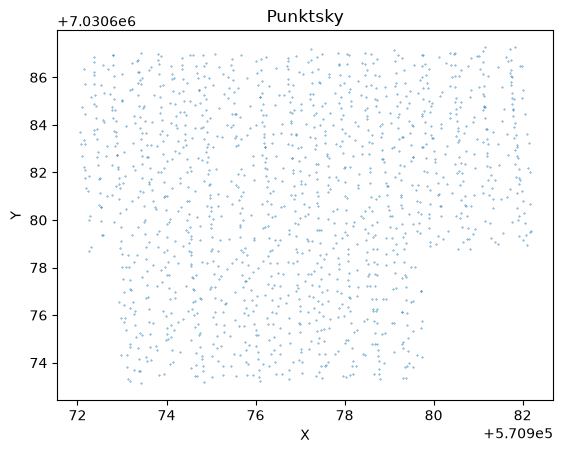

In [32]:
xy = np.vstack((las.x, las.y)).T
plt.scatter(xy[:, 0], xy[:, 1], s=0.1)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Punktsky")
plt.show()

<h2> All house roofs in roofdata <h2>

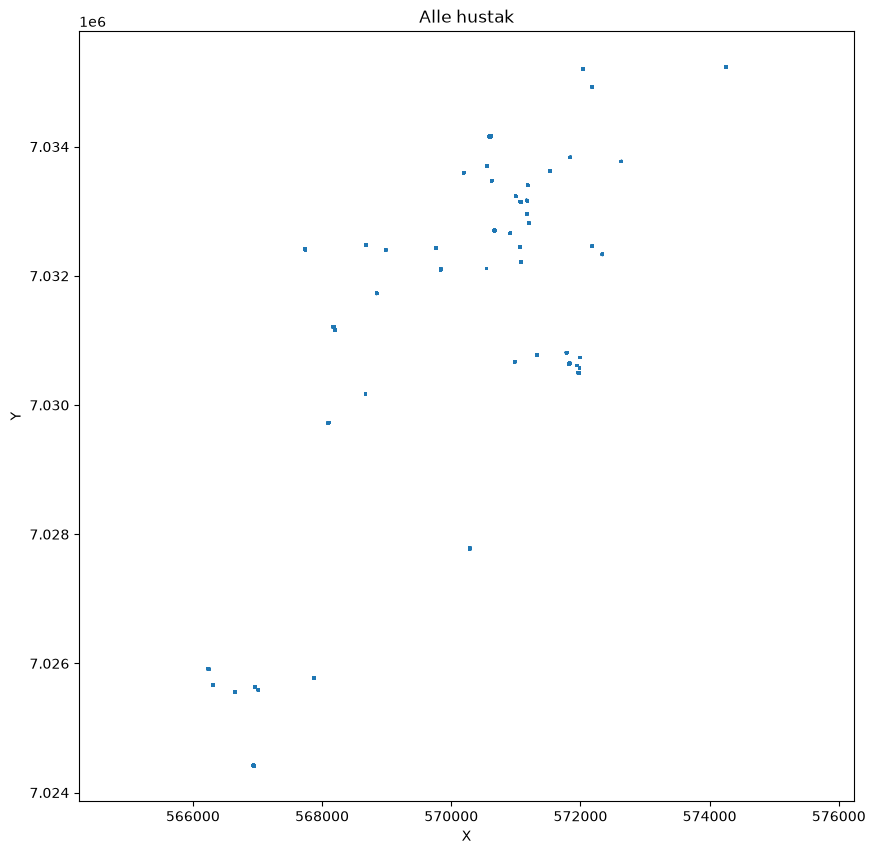

In [34]:
files = sorted(
    file for file in os.listdir(path)
    if file.lower().endswith(".laz")
)

if not files:
    raise FileNotFoundError(f"Fant ingen .laz-filer i {path}")

xy_parts = []

for file in files:
    las_file = laspy.read(os.path.join(path, file))
    xy_parts.append(np.column_stack((las_file.x, las_file.y)))

xy = np.concatenate(xy_parts, axis=0)

plt.figure(figsize=(10, 10))
plt.scatter(xy[:, 0], xy[:, 1], s=0.1)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Alle hustak")
plt.axis("equal")
plt.show()

Coordiante bounds for the .laz-data


In [35]:
min_x = np.min(xy[:, 0])
max_x = np.max(xy[:, 0])
min_y = np.min(xy[:, 1])
max_y = np.max(xy[:, 1])
print(f"Coordinate bounds: X: [{min_x}, {max_x}], Y: [{min_y}, {max_y}]")

Coordinate bounds: X: [566223.87, 574253.35], Y: [7024412.59, 7035250.13]


<h2>3D visualization of a single .laz-fil<h2>

In [ ]:
path = "data/sample_roofdata_50"

las = laspy.read(path + "/10444144.laz")

xyz = np.vstack((las.x, las.y, las.z))


pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(xyz.T)

pcd_center = pcd_o3d.get_center()

pcd_o3d.translate(-pcd_center)

o3d.visualization.draw_geometries([pcd_o3d])

: 

In [ ]:
path = "data/sample_roofdata_50"

files = sorted(
    file for file in os.listdir(path)
    if file.lower().endswith(".laz")
)

if not files:
    raise FileNotFoundError(f"Fant ingen .laz-filer i {path}")

xyz_parts = []

for file in files:
    las_file = laspy.read(os.path.join(path, file))
    xyz_parts.append(
        np.column_stack((las_file.x, las_file.y, las_file.z))
    )

xyz = np.concatenate(xyz_parts, axis=0)

print(f"Antall LAZ-filer: {len(files)}")
print(f"Antall punkter totalt: {len(xyz)}")

pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(xyz)

pcd_o3d.translate(-pcd_o3d.get_center())

o3d.visualization.draw_geometries([pcd_o3d])

Antall LAZ-filer: 50
Antall punkter totalt: 134603


: 

<h1>FKB-data</h1>

In [ ]:
path = "data/Basisdata_5001_Trondheim_5972_FKB-Bygning_GML.gml"
fkb = gpd.read_file(path, engine="pyogrio")


/opt/homebrew/Caskroom/miniconda/base/envs/3d_modellering/lib/python3.12/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'Basisdata_5001_Trondheim_5972_FKB-Bygning_GML.gml': 'AnnenBygning' (default), 'Bygning', 'BygningBru', 'BygningsavgrensningTiltak', 'Bygningsdelelinje', 'Bygningslinje', 'Fasadeliv', 'FiktivBygningsavgrensning', 'Grunnmur', 'Hjelpelinje3D', 'Låvebru', 'Mønelinje', 'TakMur', 'Takkant', 'Takoverbygg', 'TakoverbyggKant', 'Takplatå', 'TakplatåTopp', 'Taksprang', 'TaksprangBunn', 'TrappBygg', 'VeggFrittstående', 'Veranda'. Specify layer parameter to avoid this warning.
  result = read_func(


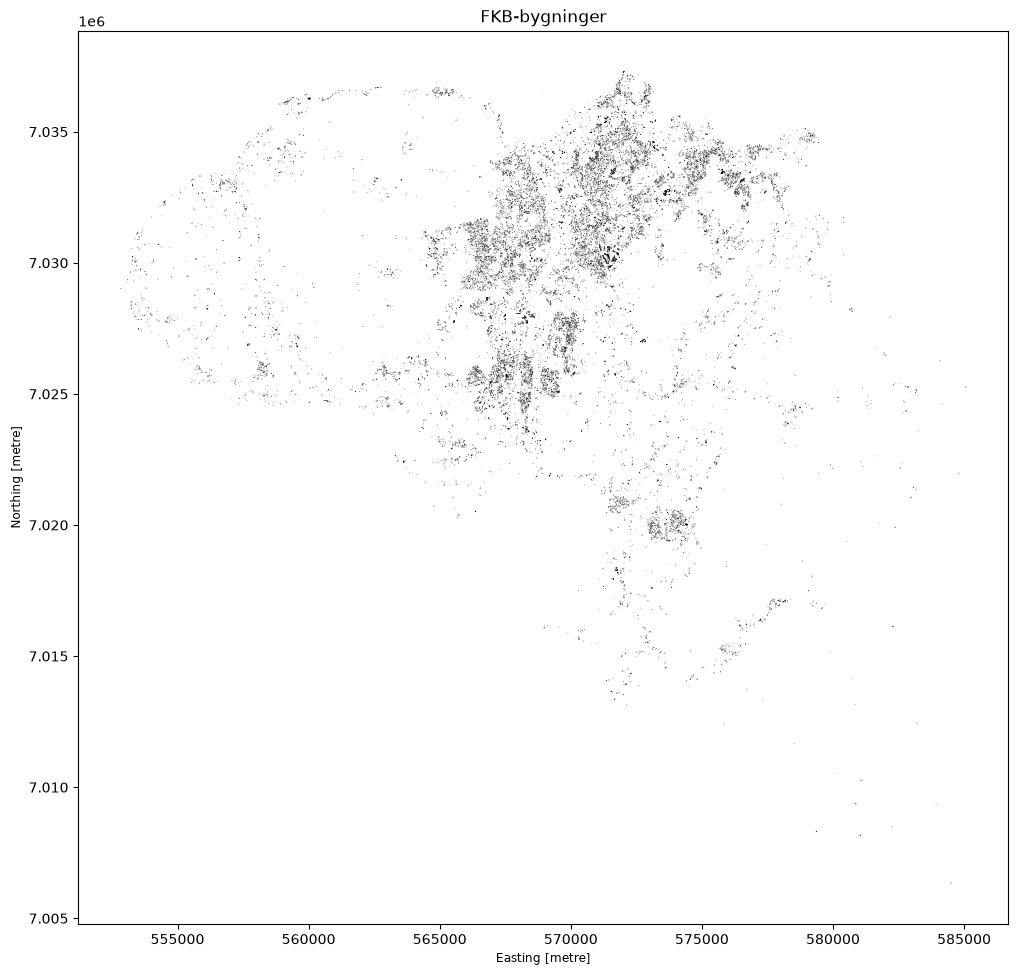

In [37]:
fig, ax = plt.subplots(figsize=(12, 12))

fkb.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("FKB-bygninger")
ax.set_aspect("equal")
plt.show()

In [ ]:
path = "data/Basisdata_5001_Trondheim_5972_FKB-Bygning_GML.gml"
bbox = (min_x, min_y, max_x, max_y) #From the bounds of the point cloud

takkant = gpd.read_file(
    path,
    layer="Takkant",
    bbox=bbox,
    engine="pyogrio"
)

monelinje = gpd.read_file(
    path,
    layer="Mønelinje",
    bbox=bbox,
    engine="pyogrio"
)

bygningslinje = gpd.read_file(
    path,
    layer="Bygningslinje",
    bbox=bbox,
    engine="pyogrio"
)

print("Takkant:", len(takkant))
print("Mønelinje:", len(monelinje))
print("Bygningslinje:", len(bygningslinje))

Takkant: 147394
Mønelinje: 61484
Bygningslinje: 45893


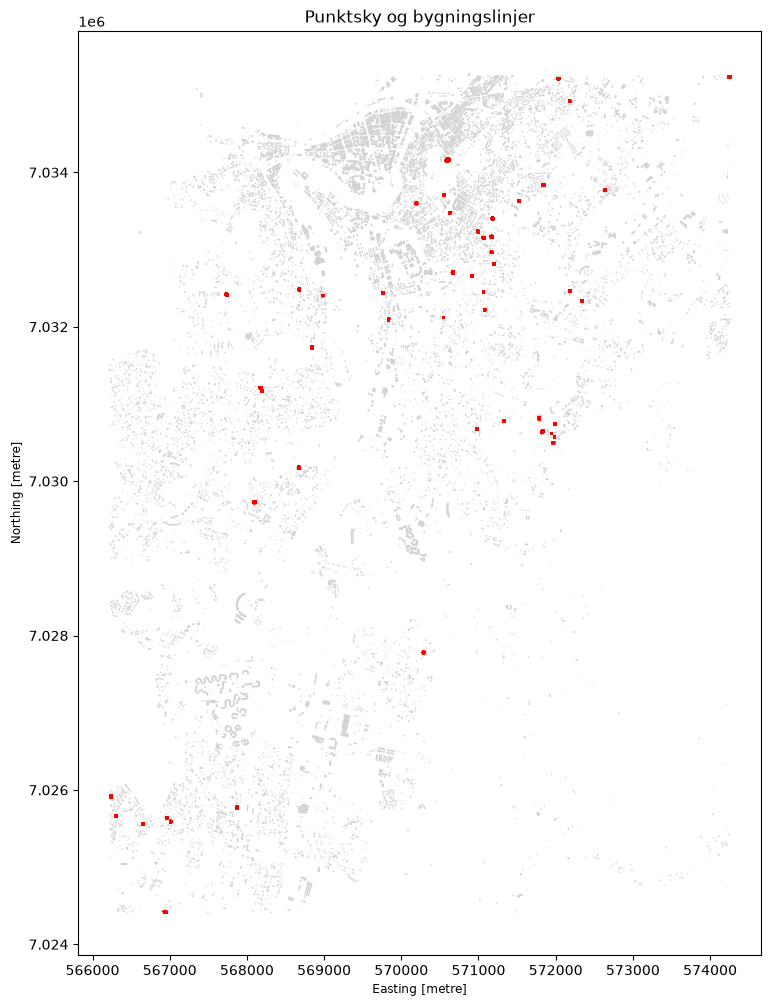

In [ ]:
fig, ax = plt.subplots(figsize=(12, 12))

bygningslinje.plot(
    ax=ax,
    color="lightgray",
    linewidth=1
)

ax.scatter(
    xy[:, 0],
    xy[:, 1],
    s=0.1,
    color="red",
    zorder=2
)

ax.set_aspect("equal")
ax.set_title("Punktsky og bygningslinjer")

plt.show()